In [5]:
import numpy as np
import os
from tqdm import tqdm
import matplotlib.pyplot as plt

In [ ]:
#path = '/home/kale-chen/Documents/PET/MDA_04112026/run1singles.ldat'
path = '/home/kale-chen/Documents/PET/MiniPET/singles/old/Run118_singles.ldat'
row_size = 16
num_rows = os.path.getsize(path) // row_size
dtypes = np.dtype([('time', np.int64), 
                    ('energy', np.float32), 
                    ('id', np.int32)])
data = np.memmap(path, dtype=dtypes, mode='r', shape=(num_rows,))
print(data[0:3])
print(num_rows)

[(6470975042476, 21.784122 , 262774) (6470975042278, 17.4608   , 262780)
 (6470975046675,  1.1360435, 262769)]
378660615


In [29]:
eventcounts = np.zeros(6144, dtype = np.int32)
for i in tqdm(range(0, len(data), 1000000)):
    chunk = data[i:i+1000000]
    ids = chunk['id']
    mask = ids > 10000
    idls = (ids[mask] - 131072) % 3072 + 3072
    idrs = ids[~mask] % 3072
    np.add.at(eventcounts, idls, 1)
    np.add.at(eventcounts, idrs, 1)
print(eventcounts, np.sum(eventcounts))


100%|██████████| 306/306 [00:12<00:00, 24.07it/s]

[68069 71870 50156 ... 46930 41846 38066] 305135102


100%|██████████| 306/306 [00:02<00:00, 146.81it/s]


54518


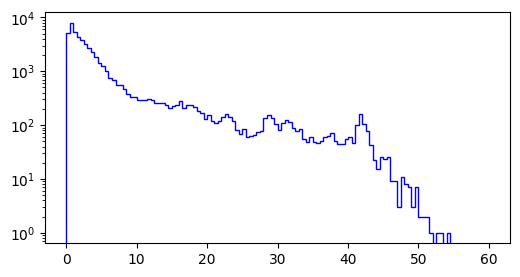

In [38]:
idl = 1
energies = np.zeros(eventcounts[idl + 3072],dtype = np.float32)
writehead = 0
for i in tqdm(range(0, len(data), 1000000)):
    chunk = data[i:i+1000000]
    ids = chunk['id']
    mask = ((ids - 131072) % 3072 == idl) & (ids > 10000)
    chunk = chunk[mask]
    energies[writehead:writehead+len(chunk)] = chunk['energy']
    writehead += len(chunk)
print(writehead)
plt.figure(figsize = (6, 3))
plt.hist(energies, bins = np.linspace(0, 60, 121), color = 'blue', histtype = 'step')
plt.yscale('log')
plt.show()


In [59]:
lookat = data[23:40]
print(lookat)

[(9666217860673,  2.4660912 ,   5010) (9666217859174, 10.075108  ,   5027)
 (9666217858914, 15.088264  ,   5022) (9666217858785, 11.603306  ,   5013)
 (9666217860869,  4.4003906 ,   5023) (9666217864145,  1.45261   ,   5020)
 (9666217863010,  1.8779411 ,   5029) (9666217862890,  2.3451653 ,   5028)
 (9666217863788,  0.7643471 ,   5024) (9666217864413,  1.0772247 ,   5012)
 (9666217868570,  0.8014717 ,   5026) (9666217868938,  0.32956314,   5015)
 (9666217872062, 27.91143   , 139568) (9666217875675,  3.5748901 , 139565)
 (9666217877706,  1.4303017 , 139567) (9666217876314,  1.9498787 , 139580)
 (9666217873121,  7.984047  , 139583)]


In [56]:
lookat = data['id'][23:35]
print(lookat)
lookatL = lookat[lookat > 10000]
lookatR = lookat[lookat <= 10000]
print(lookatL % 128)
print(lookatR % 128)

[5010 5027 5022 5013 5023 5020 5029 5028 5024 5012 5026 5015]
[]
[18 35 30 21 31 28 37 36 32 20 34 23]
